# Neural rendering of the Phong model

A conditional GAN renders a sphere with the Phong model from the scene parameters. The reference images come from the
renderer of the task (`renderer/`).

- Data set: 3000 images of 128 x 128 (job `data-v1`), 2400 train images and 600 test images.
- Metrics: FLIP, LPIPS, SSIM and the Hausdorff distance between Canny edges (`metrics.py`).
- All results come from Kaggle jobs. `WORKLOG.md` has the list of the jobs.

In [1]:
import warnings

import pandas as pd
from IPython.display import Image, display

from metrics import METRICS, load_summaries, metric_correlation, plot_histories, scores_by_size, sphere_diameter

warnings.filterwarnings("ignore")
RESULTS = "results"
params = pd.read_csv(f"{RESULTS}/data-v1/params.csv")
params.groupby("split").size()

split
test      600
train    2400
dtype: int64

## Data

Each scene has a random sphere position, diffuse color, shininess and light position. The full sphere is always in the
camera view. The preview shows 32 train images.

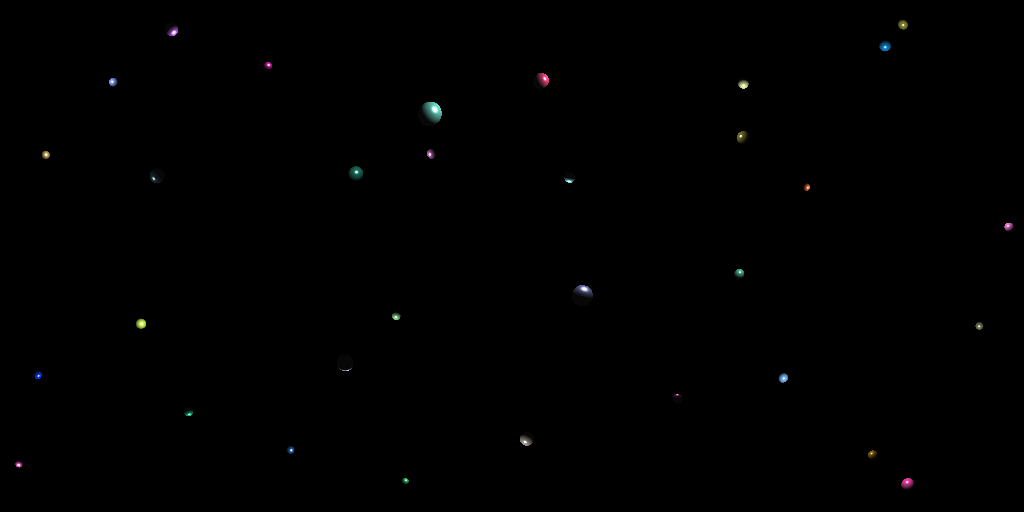

In [2]:
display(Image(f"{RESULTS}/data-v1/preview.png"))

The diameter of the sphere in the image (pixels). Most spheres are small. Thus most pixels of an image are background.

In [3]:
diameter = pd.Series(sphere_diameter(params), name="diameter (px)")
diameter.describe().round(1).to_frame().T

,count,mean,std,min,25%,50%,75%,max
diameter (px),3000.0,11.3,4.6,6.8,8.7,10.0,12.2,76.8


## Main result

The network in the renderer (job `render-v1`): the renderer draws the Phong image and the image of the generator of
`gan-v2a` for the same scene. The scores are the mean values over the 600 test scenes.

In [4]:
render = pd.read_json(f"{RESULTS}/render-v1/summary.json", typ="series")
pd.DataFrame([render[METRICS]], index=["neural_renderer"]).astype(float).round(5)

,FLIP,LPIPS,SSIM,Hausdorff
neural_renderer,0.00074,0.00099,0.9995,1.50079


## Experiments

All variants use the same data, 2200 train images and 200 tune images. The checkpoint with the best tune LPIPS is
scored on the 600 test images. One change for each variant:

| Codename | Change from `gan-v1a` |
|---|---|
| `gan-v1a` | main model: GAN weight 5, L1 weight 100, features, relative coordinates, mirror augmentation, 40000 steps |
| `gan-v1b` | only L1, no GAN |
| `gan-v1c` | raw parameters as input, no relative coordinates (hint 1 of the task) |
| `gan-v1d` | no relative coordinates |
| `gan-v1e` | GAN weight 1 |
| `gan-v1f` | seed 1 |
| `gan-v2a` | 100000 steps |
| `gan-v2b` | no mirror augmentation |
| `gan-v3a` | only L1, 100000 steps |
| `gan-v3b` | 100000 steps, seed 1 |

These scores use the float output of the network, not the 8-bit image of the renderer (see the analysis of FLIP below).

In [5]:
RUNS = ["gan-v1a", "gan-v1b", "gan-v1c", "gan-v1d", "gan-v1e", "gan-v1f", "gan-v2a", "gan-v2b", "gan-v3a", "gan-v3b"]
summaries = load_summaries(RESULTS, RUNS)
summaries[[*METRICS, "best_step", "train_minutes", "ms_per_image"]].round(5)

,FLIP,LPIPS,SSIM,Hausdorff,best_step,train_minutes,ms_per_image
codename,,,,,,,
gan-v1a,0.00156,0.00117,0.99927,1.60184,30000,71.7,3.85
gan-v1b,0.00131,0.00197,0.99940,2.09254,40000,47.1,3.53
gan-v1c,0.00255,0.00393,0.99772,2.37898,40000,68.4,4.04
gan-v1d,0.00186,0.00143,0.99905,1.65113,32000,67.3,3.69
gan-v1e,0.00136,0.00134,0.99934,1.57506,40000,71.8,4.01
gan-v1f,0.00131,0.00103,0.99936,1.49797,40000,71.1,4.95
gan-v2a,0.00115,0.00099,0.99949,1.50079,80000,167.8,3.60
gan-v2b,0.00204,0.00234,0.99881,2.31603,22000,68.5,3.60
gan-v3a,0.00118,0.00156,0.99944,1.80360,100000,116.2,3.33


## Learning curves

The tune metrics every 2000 steps (40000-step runs) or 5000 steps (100000-step runs). The y axis has a log scale.

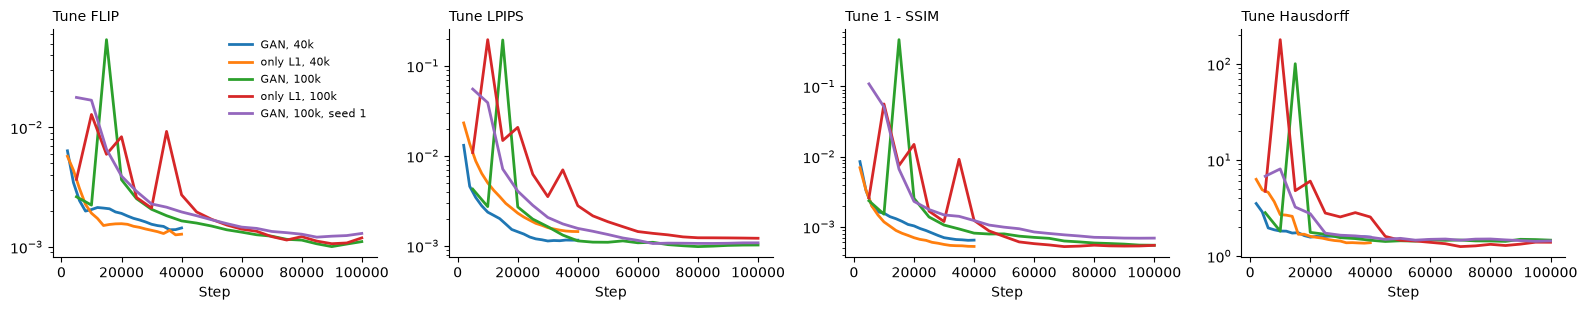

In [6]:
plot_histories(RESULTS, {"gan-v1a": "GAN, 40k", "gan-v1b": "only L1, 40k", "gan-v2a": "GAN, 100k",
                         "gan-v3a": "only L1, 100k", "gan-v3b": "GAN, 100k, seed 1"});

- The 100000-step runs have a peak of the error between the steps 10000 and 20000. The cosine schedule keeps the
  learning rate high for a longer time. The training then returns to a low error.
- After 40000 steps, the errors continue to decrease slowly until approximately the step 80000.

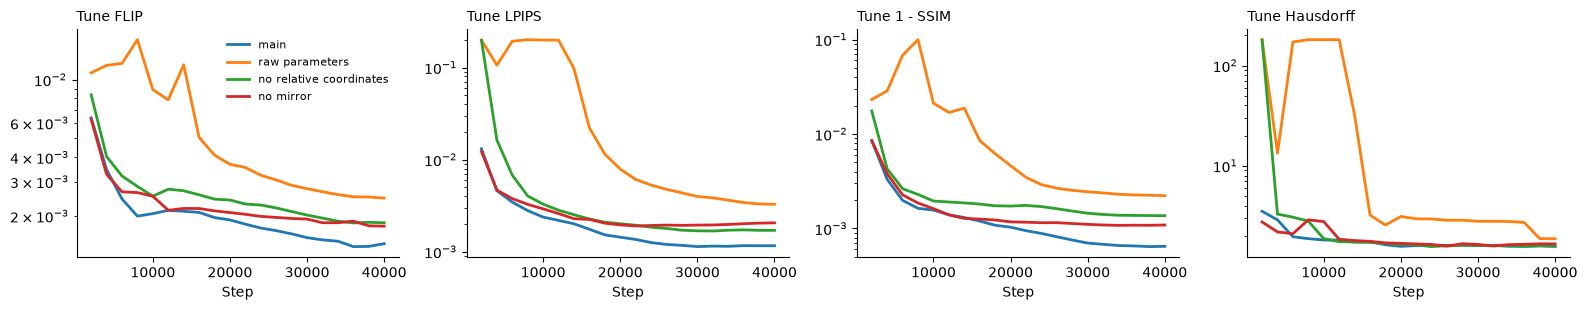

In [7]:
plot_histories(RESULTS, {"gan-v1a": "main", "gan-v1c": "raw parameters", "gan-v1d": "no relative coordinates",
                         "gan-v2b": "no mirror"});

- With the raw parameters, the network needs approximately 15000 steps to find the sphere. Its errors stay the largest.
- Without the mirror augmentation, the tune LPIPS increases after the step 20000. The network overfits the 2200 train
  images.
- Without the relative coordinates, all errors are larger than with them.

## Test images of the final model

Rows: the 2 best, 4 middle and 2 worst test images by LPIPS. The worst images have the light behind the sphere. Only a
thin bright edge is visible.

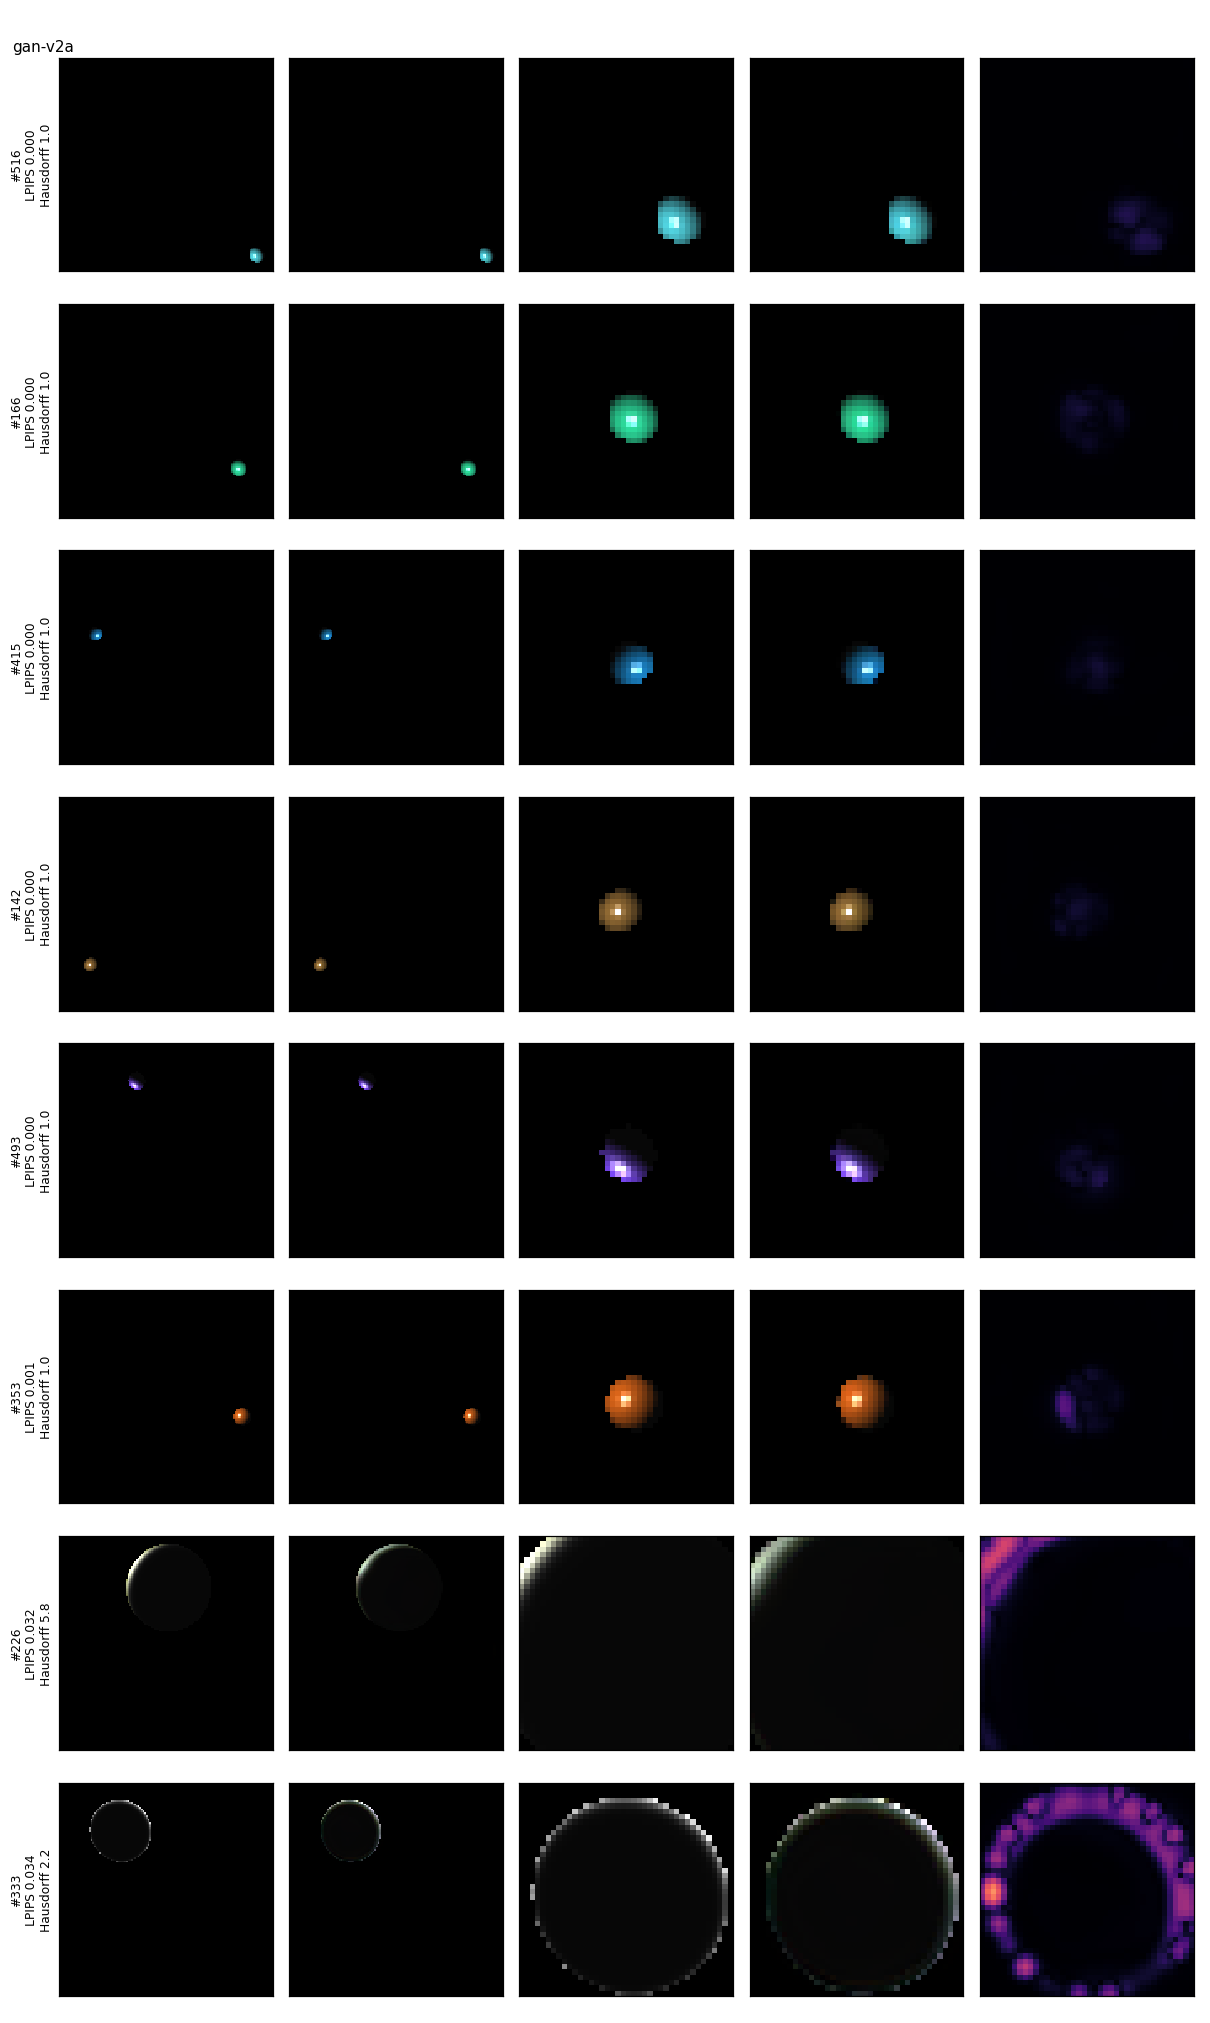

In [8]:
display(Image(f"{RESULTS}/gan-v2a/examples.png"))

## The network in the renderer

`renderer/src/neural_window.py` shows the Phong image (left) and the network image (right) for each scene. Start it
with `python renderer/src/main.py --generator <path to generator.pt>`. The preview shows 8 test scenes and a 4x zoom of
the sphere (Phong, network).

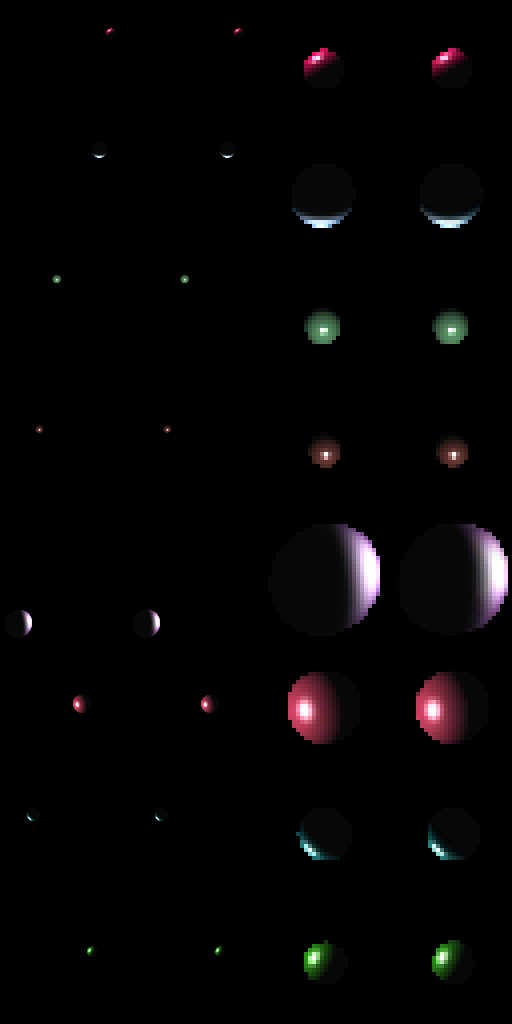

In [9]:
display(Image(f"{RESULTS}/render-v1/preview.png"))

In [10]:
render[["phong_equal_to_data_set", "max_difference_to_training_predictions", "ms_per_image_cpu"]].to_frame("value")

,value
phong_equal_to_data_set,3000
max_difference_to_training_predictions,1.0
ms_per_image_cpu,53.9


- All 3000 Phong images of the renderer are equal to the data set.
- The network image of the renderer differs from the training predictions by 1/255 or less.
- The network takes 54 ms for one image on the CPU.

# Analysis of the metrics

The question of the task: do all metrics show the quality well?

## Change test

Simple changes of the 600 reference images, scored against the reference.

In [11]:
pd.read_csv(f"{RESULTS}/render-v1/change-test.csv", index_col=0).round(4)

,FLIP,LPIPS,SSIM,Hausdorff
same image,0.0000,0.0000,1.0000,0.0000
shift 2 px,0.0052,0.0164,0.9897,2.5756
shift 10 px,0.0115,0.0811,0.9747,14.2769
swap R and B,0.0027,0.0212,0.9974,0.9749
50% darker,0.0055,0.0299,0.9949,1.4424
black image,0.0067,0.1959,0.9842,181.0193


- A black image gets a better FLIP than a shift of 10 px, and an SSIM of 0.98. FLIP and SSIM are mean values over all
  pixels, and most pixels are background.
- LPIPS gives the black image the worst score. LPIPS sees the missing object.
- The Hausdorff distance sees only the position of the edges. A swap of R and B moves the edges very little.
- A black image has no edges. Then the Hausdorff distance is not defined, and `metrics.hausdorff` gives the image
  diagonal (181 px).

## Full image and crop

The same network images, scored on the full image and on a 64 x 64 crop around the sphere.

In [12]:
full = pd.read_csv(f"{RESULTS}/render-v1/scores.csv")
crop = pd.read_csv(f"{RESULTS}/render-v1/scores-crop.csv")
pd.DataFrame({"full image": full[METRICS].mean(), "crop 64x64": crop[METRICS].mean()}).T.round(5)

,FLIP,LPIPS,SSIM,Hausdorff
full image,0.00074,0.00099,0.99950,1.50079
crop 64x64,0.00295,0.00191,0.99782,1.50079


The crop has 4 times fewer pixels. FLIP becomes 4 times larger, LPIPS 2 times larger. The error of the network did not
change. Thus the value of these metrics depends on the background area.

## FLIP of the float output and of the 8-bit image

The training scores the float output of the network. The renderer saves 8-bit PNG images.

In [13]:
training = pd.read_csv(f"{RESULTS}/gan-v2a/scores.csv")
table = pd.DataFrame({"float output": training[METRICS].mean(), "8-bit image": full[METRICS].mean()}).T
table.loc["8-bit is better (share of images)"] = (full[METRICS] < training[METRICS]).mean()
table.round(5)

,FLIP,LPIPS,SSIM,Hausdorff
float output,0.00115,0.00099,0.99949,1.50079
8-bit image,0.00074,0.00099,0.99950,1.50079
8-bit is better (share of images),1.00000,0.51167,0.01167,0.00000


The 8-bit image has a smaller FLIP for all 600 images. The rounding sets very small background values to 0. The eye
cannot see these values, but FLIP adds them over the large background. The other metrics do not change.

## Sphere size

Mean metrics of the final model for groups of test images with a similar sphere diameter.

In [14]:
scores_by_size(full, params).round(5)

,images,FLIP,LPIPS,SSIM,Hausdorff
diameter (px),,,,,
"[6, 8)",57,0.00038,0.00025,0.99988,1.06529
"[8, 10)",249,0.00045,0.00048,0.99983,1.15364
"[10, 13)",171,0.00060,0.00078,0.99967,1.44915
"[13, 20)",100,0.00103,0.00154,0.99921,2.03436
"[20, 128)",23,0.00451,0.00751,0.99500,4.40260


All errors increase with the sphere size. A large sphere has more pixels with a possible error. Thus a mean score also
depends on the distribution of the sphere sizes in the test set.

## Agreement of the metrics

Rank correlation (Spearman) over the 600 test images. FLIP, LPIPS and Hausdorff are errors. SSIM is a similarity, so a
good agreement gives a negative value with SSIM.

In [15]:
metric_correlation(full).round(2)

,FLIP,LPIPS,SSIM,Hausdorff
FLIP,1.00,0.54,-0.61,0.32
LPIPS,0.54,1.00,-0.82,0.40
SSIM,-0.61,-0.82,1.00,-0.41
Hausdorff,0.32,0.40,-0.41,1.00


LPIPS and SSIM agree well (-0.82). The Hausdorff distance agrees least with the other metrics (0.3-0.4). It sees only
the edges, and the Canny edges of a dark sphere are not stable.

## GAN against only L1, and the seed noise

The same model with different seeds shows the random difference between two trainings.

In [16]:
pairs = {"GAN, 40k": "gan-v1a", "GAN, 40k, seed 1": "gan-v1f", "only L1, 40k": "gan-v1b",
         "GAN, 100k": "gan-v2a", "GAN, 100k, seed 1": "gan-v3b", "only L1, 100k": "gan-v3a"}
summaries.loc[list(pairs.values()), METRICS].set_axis(list(pairs), axis=0).round(5)

,FLIP,LPIPS,SSIM,Hausdorff
"GAN, 40k",0.00156,0.00117,0.99927,1.60184
"GAN, 40k, seed 1",0.00131,0.00103,0.99936,1.49797
"only L1, 40k",0.00131,0.00197,0.99940,2.09254
"GAN, 100k",0.00115,0.00099,0.99949,1.50079
"GAN, 100k, seed 1",0.00142,0.00109,0.99930,1.58711
"only L1, 100k",0.00118,0.00156,0.99944,1.80360


- At 40000 steps, only L1 has a better FLIP and SSIM, and the GAN has a better LPIPS and Hausdorff distance. The
  metrics do not agree.
- At 100000 steps, `gan-v2a` is better than only L1 in all four metrics. But the second seed of the GAN has a worse FLIP
  and SSIM than only L1.
- The difference between two seeds is approximately as large as the difference between the GAN and only L1 in FLIP and
  SSIM. In LPIPS and the Hausdorff distance, the GAN is better with both seeds.

## Answer

Not all metrics show the quality well for these images.

- FLIP and SSIM are mean values over all pixels. The background is most of the image, thus a black image gets good
  scores. Their values also change with the crop size and with the 8-bit rounding of an invisible background error.
- LPIPS is the most useful metric here. It sees a missing object, and it agrees best with the other metrics.
- The Hausdorff distance sees only the edge position. It does not see a color error, and it is not defined for an
  image without edges.
- A good comparison uses more than one metric, and a look at the worst images.